# Libraries

In [1]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.5/29.5 MB 54.8 MB/s  0:00:00


In [2]:
!pip install torch-geometric

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 10.7 MB/s  0:00:00


In [3]:
!pip install datasets

# Data Loader

In [4]:
from datasets import load_dataset
import pandas as pd

esol = load_dataset("HUBioDataLab/esol")
df = esol["train"].to_pandas()

smiles = df["smiles"]
targets = df["measured log solubility in mols per litre"]

esol.csv:   0%|          | 0.00/90.8k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1128 [00:00<?, ? examples/s]

In [5]:
from rdkit import Chem
import torch
import torch.nn as nn
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
import random

data = []
atom_types = ["C", "N", "O", "F", "S", "Cl", "Br", "P"]

def one_hot_element(atom):
    return [int(atom.GetSymbol() == element) for element in atom_types]

#Convert SMILES into PyTorch Geometric graph data
def smiles_to_graph(smiles,target):
    mol = Chem.MolFromSmiles(smiles)
    atom_features = []
    for atom in mol.GetAtoms():
      atom_features.append(one_hot_element(atom) + [int(atom.GetHybridization()), atom.GetTotalNumHs(), atom.GetDegree(), int(atom.GetIsAromatic())])
    atom_features_tensor = torch.tensor(atom_features, dtype=torch.float32)
    edge_index = []
    for bond in mol.GetBonds():
      edge_index.append([bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()])
      edge_index.append([bond.GetEndAtomIdx(), bond.GetBeginAtomIdx()])
    edge_index_tensor = torch.tensor(edge_index, dtype=torch.long).t().reshape(2,-1) #transpose, reshape if it is empty
    target_tensor = torch.tensor([target], dtype=torch.float32)
    molecule_data = Data(x = atom_features_tensor, edge_index = edge_index_tensor, y=target_tensor)
    return molecule_data

#Construct molecular graphs
for smiles, target in zip(df["smiles"], df["measured log solubility in mols per litre"]):
  mol_data = smiles_to_graph(smiles, target)
  data.append(mol_data)

random.seed(42)
random.shuffle(data)
torch.manual_seed(42)

train_loader = DataLoader(data[:int(0.8*len(data))], batch_size=32, shuffle=True)
val_loader = DataLoader(data[int(0.8*len(data)):int(0.9*len(data))], batch_size=32, shuffle=False)
test_loader = DataLoader(data[int(0.9*len(data)):], batch_size=16, shuffle=False)


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [6]:
print("Train:", len(train_loader.dataset))
print("Validation:", len(val_loader.dataset))
print("Test:", len(test_loader.dataset))

Train: 902
Validation: 113
Test: 113


# GCN

In [8]:
from torch_geometric.nn import GCNConv
from torch_geometric.nn import global_mean_pool

class GCN(nn.Module):
  #Define learnable layers
  def __init__(self, gnn_features, hidden_features1, hidden_features2):
    super().__init__()
    self.gcn_layer1 = GCNConv(gnn_features, hidden_features1)
    self.gcn_layer2 = GCNConv(hidden_features1,hidden_features2)
    self.ff = nn.Linear(hidden_features2, 1)
    self.relu = nn.ReLU()
    self.dropout = nn.Dropout(p=0.2)

  def forward(self, data):
    #How layers are applied
    layer_1 = self.gcn_layer1(data.x, data.edge_index)
    layer_1_2 = self.relu(layer_1)
    layer_1_3 = self.dropout(layer_1_2)
    layer_2 = self.gcn_layer2(layer_1_3, data.edge_index)
    layer_2_1 = self.relu(layer_2)
    layer_2_2 = global_mean_pool(layer_2_1, data.batch)
    layer_3 = self.ff(layer_2_2)
    return layer_3


In [20]:
import torch.optim as optim

epochs = 300

gcn_model = GCN(data[0].x.shape[1], 32, 64)
loss_fn = nn.MSELoss()
optimizer = optim.Adam(gcn_model.parameters(), lr=0.001)
best_validation_loss = float("inf")

train_loss = []
val_loss = []
for epoch in range(epochs):
  total_train_loss = 0
  gcn_model.train()
  for batch in train_loader:
    optimizer.zero_grad()
    prediction = gcn_model(batch).squeeze(-1)
    loss = loss_fn(prediction, batch.y)
    loss.backward()
    optimizer.step()
    total_train_loss += loss.item()
  average_train_loss = total_train_loss/len(train_loader)
  train_loss.append(average_train_loss)

  total_validation_loss = 0
  gcn_model.eval()

  with torch.no_grad():
    for batch in val_loader:
      prediction = gcn_model(batch).squeeze(-1)
      loss = loss_fn(prediction, batch.y)
      total_validation_loss += loss.item()
    average_validation_loss = total_validation_loss/len(val_loader)
    val_loss.append(average_validation_loss)
    print(f"Epoch {epoch+1}: Train Loss = {average_train_loss:.4f}, Validation Loss = {average_validation_loss:.4f}")


  if average_validation_loss < best_validation_loss:
    best_validation_loss = average_validation_loss
    best_validation_epoch = epoch

    torch.save(gcn_model.state_dict(), "best_gcn_model.pth")

print(f"Best validation loss: {best_validation_loss:.4f}")
print(f"Best epoch: {best_validation_epoch + 1}")

Epoch 1: Train Loss = 9.4231, Validation Loss = 5.7027
Epoch 2: Train Loss = 4.5741, Validation Loss = 4.2284
Epoch 3: Train Loss = 4.0931, Validation Loss = 3.9059
Epoch 4: Train Loss = 3.8598, Validation Loss = 3.5909
Epoch 5: Train Loss = 3.7604, Validation Loss = 3.3414
Epoch 6: Train Loss = 3.5612, Validation Loss = 3.2507
Epoch 7: Train Loss = 3.5489, Validation Loss = 3.0516
Epoch 8: Train Loss = 3.4366, Validation Loss = 2.9546
Epoch 9: Train Loss = 3.3921, Validation Loss = 2.8710
Epoch 10: Train Loss = 3.1713, Validation Loss = 2.8408
Epoch 11: Train Loss = 3.0575, Validation Loss = 2.6772
Epoch 12: Train Loss = 2.9753, Validation Loss = 2.5738
Epoch 13: Train Loss = 2.8833, Validation Loss = 2.5334
Epoch 14: Train Loss = 2.9039, Validation Loss = 2.5211
Epoch 15: Train Loss = 2.7797, Validation Loss = 2.4286
Epoch 16: Train Loss = 2.6133, Validation Loss = 2.3483
Epoch 17: Train Loss = 2.6551, Validation Loss = 2.2871
Epoch 18: Train Loss = 2.5228, Validation Loss = 2.2393
E

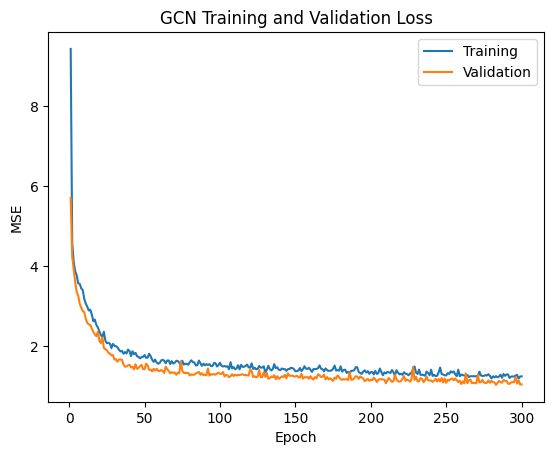

In [21]:
import matplotlib.pyplot as plt
epochs_train = range(1, len(train_loss) + 1)
epochs_val = range(1, len(val_loss) + 1)

plt.plot(epochs_train, train_loss, label="Training")
plt.plot(epochs_val, val_loss, label="Validation")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("GCN Training and Validation Loss")
plt.legend()
plt.show()

In [22]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

gcn_model.load_state_dict(torch.load("best_gcn_model.pth", weights_only=True))
gcn_model.eval()

all_predictions = []
all_targets = []

with torch.no_grad():
  for batch in test_loader:
    prediction = gcn_model(batch).squeeze(-1)
    all_predictions.extend(prediction.tolist())
    all_targets.extend(batch.y.tolist())

  rmse = root_mean_squared_error(all_targets, all_predictions)
  mae = mean_absolute_error(all_targets, all_predictions)
  r2 = r2_score(all_targets, all_predictions)
  print(f"RMSE: {rmse} \nMAE:{mae} \nR2: {r2} ")

RMSE: 1.129649928113675 
MAE:0.8585153859833964 
R2: 0.6799997988819089 
